# 🔥 Day 11 — PyTorch + MLP Training Loop
### 2 Hours

---

## The shift from Day 10

Yesterday you built everything from scratch in NumPy. Today you hand that off to PyTorch — a production-grade deep learning framework used at companies like Meta, Tesla, and OpenAI.

**What PyTorch gives you that NumPy does not:**

| Feature | NumPy | PyTorch |
|---------|-------|---------|
| Automatic gradients | ❌ manual | ✅ Autograd |
| GPU acceleration | ❌ | ✅ `.to(device)` |
| Model building blocks | ❌ | ✅ `nn.Module` |
| Optimisers | ❌ manual | ✅ Adam, SGD, etc. |
| Data pipelines | ❌ | ✅ DataLoader |

**Everything from Day 10 still applies.** PyTorch is not replacing the concepts — it is replacing the boilerplate so you can focus on architecture and experiments.

**Goal today:** Train an MLP on MNIST and reach >97% test accuracy.

---
> 💡 Every task in this notebook builds toward the MNIST lab. The concepts are not abstract exercises — they are the exact tools you will use in Tasks 16–20.

In [1]:
!pip3 install torch torchvision --index-url https://download.pytorch.org/whl/cpu

Looking in indexes: https://download.pytorch.org/whl/cpu


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

plt.style.use('seaborn-v0_8')

# Device setup — use GPU if available, otherwise CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch version: {torch.__version__}')
print(f'Using device:    {device}')

PyTorch version: 2.12.0
Using device:    cpu


In [3]:
# Check if PyTorch is installed
print("PyTorch Version:", torch.__version__)

# Verify MPS (Metal Performance Shaders) GPU acceleration is available
print("MPS Available:", torch.backends.mps.is_available())

PyTorch Version: 2.12.0
MPS Available: True


In [4]:
# Set the device to MPS
device = torch.device("mps")

# Move your model or tensor to the GPU
my_tensor = torch.rand((1000, 1000)).to(device)


---
# Part 1 — PyTorch Tensors

## What is a Tensor?

A tensor is PyTorch's fundamental data structure — it is the PyTorch equivalent of a NumPy array. Conceptually identical: an n-dimensional array of numbers. Practically very different: tensors can live on a GPU, track operations for automatic differentiation, and integrate with PyTorch's model-building machinery.

```
Scalar   → 0-dimensional tensor    torch.tensor(3.14)
Vector   → 1-dimensional tensor    torch.tensor([1, 2, 3])
Matrix   → 2-dimensional tensor    torch.tensor([[1,2],[3,4]])
Volume   → 3-dimensional tensor    shape (batch, height, width)
```

## Every Tensor has Three Properties

| Property | What it tells you | Example |
|----------|-------------------|---------|
| `.shape` | Dimensions | `torch.Size([28, 28])` |
| `.dtype` | Data type | `torch.float32` |
| `.device` | Where it lives | `device(cpu)` or `device(cuda:0)` |

## The NumPy Bridge — and the Memory Sharing Trap

Converting between NumPy and PyTorch is common. But there is a gotcha:

```python
arr = np.array([1.0, 2.0, 3.0])
t   = torch.from_numpy(arr)    # shares memory with arr

arr[0] = 99.0
print(t)   # → tensor([99.,  2.,  3.])  ← changed too!
```

`torch.from_numpy()` **shares memory** — modifying the NumPy array modifies the tensor.  
`torch.tensor(arr)` **copies** — safe but uses more memory.  
Rule: use `torch.tensor()` when you want an independent copy.

In [5]:
# ── TASK 1 — Tensors, properties, NumPy bridge ───────────────────────────────
#
# 1. Create a 1D tensor from the list [1.0, 2.0, 3.0, 4.0, 5.0]
# 2. Create a 2D tensor (3×3) of random floats using torch.randn
# 3. For each tensor, print shape, dtype, device
# 4. Demonstrate the memory sharing trap:
#      a. Create a NumPy array [10.0, 20.0, 30.0]
#      b. Make a tensor with torch.from_numpy()
#      c. Modify arr[0] = 99.0
#      d. Print the tensor — show it changed too
#      e. Repeat with torch.tensor() — show it did NOT change

# YOUR CODE HERE
t1 = torch.tensor([1.0, 2.0, 3.0, 4.0, 5.0])
print(t1, t1.shape, t1.dtype, t1.device)

t2 = torch.randn(3,3)
print(t2)

arr = np.array([10.0, 20.0, 30.0])
t_shared = torch.from_numpy(arr) 
t_copy = torch.tensor (arr)

arr[0] = 99.0
print(f'\nAfter arr[0]=99:')
print(f'  from_numpy tensor: {t_shared}  ← CHANGED')
print(f'  tensor() copy:     {t_copy}  ← unchanged')


# 📝 When would you choose torch.from_numpy() over torch.tensor()?
# ...

tensor([1., 2., 3., 4., 5.]) torch.Size([5]) torch.float32 cpu
tensor([[ 1.3170,  1.0198,  0.7042],
        [-0.5856,  1.9099, -0.1481],
        [-1.5603,  0.2769,  0.2917]])

After arr[0]=99:
  from_numpy tensor: tensor([99., 20., 30.], dtype=torch.float64)  ← CHANGED
  tensor() copy:     tensor([10., 20., 30.], dtype=torch.float64)  ← unchanged


## Tensor Operations

PyTorch tensor operations mirror NumPy closely — the key difference is that all operations are tracked for autograd.

```python
# Element-wise
a + b,  a * b,  a ** 2

# Matrix multiply (equivalent to np.matmul or @)
a @ b
torch.matmul(a, b)

# Reshape
x.reshape(4, 7)        # like np.reshape
x.view(4, 7)           # faster but requires contiguous memory

# Add/remove dimensions
x.unsqueeze(0)         # add dim at position 0
x.squeeze()            # remove all size-1 dims
```

> ⚠️ A common error: trying to do arithmetic between a CPU tensor and a GPU tensor. Both must be on the same device.

In [7]:
# ── TASK 2 — Tensor operations ───────────────────────────────────────────────
# Use A and B defined below
#
# 1. Element-wise multiply A and B, print result
# 2. Matrix multiply A @ B.T, print result and shape
# 3. Reshape A to shape (6, 2), print
# 4. Create a tensor of shape (4,), unsqueeze to (1, 4), then squeeze back to (4,)
#    Print shapes at each step
# 5. Compute row-wise sum of A (sum across columns → one value per row)
#    Use torch.sum with the right dim argument

A = torch.arange(1, 13, dtype=torch.float32).reshape(4, 3)
B = torch.ones(4, 3) * 2

print(f'A shape: {A.shape}\n{A}\n')
print(f'B shape: {B.shape}\n{B}\n')

# YOUR CODE HERE
print("Element Wise Multiplication", A * B)
print("Matrix Multiplication", A @ B.T)

A_reshaped = A.reshape(6,2)
print(A_reshaped)
# 📝 What is the difference between reshape() and view()?
# ...

A shape: torch.Size([4, 3])
tensor([[ 1.,  2.,  3.],
        [ 4.,  5.,  6.],
        [ 7.,  8.,  9.],
        [10., 11., 12.]])

B shape: torch.Size([4, 3])
tensor([[2., 2., 2.],
        [2., 2., 2.],
        [2., 2., 2.],
        [2., 2., 2.]])

Element Wise Multiplication tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.],
        [14., 16., 18.],
        [20., 22., 24.]])
Matrix Multiplication tensor([[12., 12., 12., 12.],
        [30., 30., 30., 30.],
        [48., 48., 48., 48.],
        [66., 66., 66., 66.]])
tensor([[ 1.,  2.],
        [ 3.,  4.],
        [ 5.,  6.],
        [ 7.,  8.],
        [ 9., 10.],
        [11., 12.]])


In [8]:
# ── TASK 3 — Device-aware code ───────────────────────────────────────────────
# Write code that works correctly on BOTH CPU and GPU machines
#
# 1. Create a float tensor of shape (3, 3) on the correct device
#    Use: torch.randn(3, 3).to(device)
# 2. Create another tensor on device
# 3. Multiply them together — confirm the result is also on device
# 4. Move the result back to CPU and convert to NumPy
#    Use: result.cpu().numpy()
#    (Required because numpy() fails on CUDA tensors)

# YOUR CODE HERE
# TASK 3 — Device-aware code
t_a = torch.randn(3, 3).to(device)
t_b = torch.randn(3, 3).to(device)
result = t_a @ t_b
print(f'Result device: {result.device}')

# Convert back to numpy
result_np = result.cpu().numpy()
print(f'NumPy type: {type(result_np)}')
print(f'Device used: {device}')


print(f'Device used: {device}')

# 📝 Why do you need .cpu() before .numpy()?
# ...

Result device: mps:0
NumPy type: <class 'numpy.ndarray'>
Device used: mps
Device used: mps


---
# Part 2 — Automatic Differentiation (Autograd)

## Why Autograd Exists

In Day 10 you derived and implemented every gradient by hand — six steps of chain-rule algebra for a two-layer network. For a 50-layer ResNet with millions of parameters, that is completely impossible to do by hand. Autograd does it automatically.

## How it Works

When you set `requires_grad=True` on a tensor, PyTorch starts recording every operation performed on it — building a **computational graph** in memory.

```
x (requires_grad=True)
  ↓   y = x²
  y
  ↓   z = y + 3
  z
  ↓   .backward()
x.grad  ←  ∂z/∂x  computed automatically
```

Calling `.backward()` traverses this graph in reverse — exactly the same chain rule you wrote by hand in Day 10, but computed automatically for any graph, any depth.

## The Gradient Accumulation Trap

PyTorch **adds** new gradients to existing ones rather than overwriting them. This is intentional (useful for some advanced techniques) but is the most common beginner bug:

```python
for epoch in range(3):
    loss.backward()
    # x.grad is now 3× what it should be!
    # ALWAYS call optimizer.zero_grad() before backward()
```

In [9]:
# ── TASK 4 — Autograd: verify gradient of y = x² ────────────────────────────
#
# 1. Create x = torch.tensor([3.0], requires_grad=True)
# 2. Compute y = x ** 2
# 3. Call y.backward()
# 4. Print x.grad
# 5. Verify: dy/dx = 2x, so at x=3 the gradient should be 6.0
#
# Then repeat for x = -2.0, 0.0, 5.0
# For each: compute y=x², run backward(), verify x.grad == 2*x
#
# Note: you must create a new tensor each time (or zero the grad)
# because x.grad accumulates!

# YOUR CODE HERE
for x_val in [3.0, -2.0, 0.0, 5.0]:
    x = torch.tensor([x_val], requires_grad= True)
    y = x ** 2
    y.backward()
    print(f'x={x_val:5.1f}  dy/dx (autograd)={x.grad.item():.1f}  analytical=2*x={2*x_val:.1f}  match={abs(x.grad.item() - 2*x_val) < 1e-6}')
# 📝 What does requires_grad=True tell PyTorch?
# What would happen if you forgot to set it?
# ...

x=  3.0  dy/dx (autograd)=6.0  analytical=2*x=6.0  match=True
x= -2.0  dy/dx (autograd)=-4.0  analytical=2*x=-4.0  match=True
x=  0.0  dy/dx (autograd)=0.0  analytical=2*x=0.0  match=True
x=  5.0  dy/dx (autograd)=10.0  analytical=2*x=10.0  match=True


In [10]:
# ── TASK 5 — Gradient of MSE loss for one sample ─────────────────────────────
#
# Model: y_pred = w * x   (one weight, no bias, one sample)
# Loss:  L = (w*x - y_true)²
#
# Analytical gradient: dL/dw = 2 * x * (w*x - y_true)
#
# Setup:
#   x      = 2.0  (input)
#   y_true = 6.0  (target)
#   w      = 1.0  (initial weight, requires_grad=True)
#
# 1. Compute y_pred = w * x
# 2. Compute loss   = (y_pred - y_true) ** 2
# 3. Call loss.backward()
# 4. Print w.grad
# 5. Compute the analytical gradient by hand and print it
# 6. Verify they match

x_val  = torch.tensor([2.0])
y_true = torch.tensor([6.0])
w      = torch.tensor([1.0], requires_grad=True)

# YOUR CODE HERE
y_pred = w * x_val
loss = (y_pred - y_true) ** 2
loss.backward()


analytical = 2 * x_val.item() * (w.item() * x_val.item() - y_true.item())

print(f'Autograd gradient: {w.grad.item():.4f}')
print(f'Analytical:        {analytical:.4f}')
print(f'Match:             {abs(w.grad.item() - analytical) < 1e-5}')



# 📝 If w.grad is negative, in which direction should we update w?
# (Hint: gradient descent steps in the NEGATIVE gradient direction)
# ...

Autograd gradient: -16.0000
Analytical:        -16.0000
Match:             True


In [11]:
# ── TASK 6 — The gradient accumulation bug ───────────────────────────────────
# This task demonstrates the most common PyTorch mistake
#
# Setup: same as Task 5
#
# Part A — WITHOUT zero_grad (broken)
# Call loss.backward() THREE times without zeroing gradients
# Print w.grad after each call
# Show that gradients accumulate (add up)
#
# Part B — WITH zero_grad (correct)
# Call loss.backward() three times BUT zero the gradient before each call
# Print w.grad after each call
# Show that gradients are consistent each time

w_buggy = torch.tensor([1.0], requires_grad=True)
y_pred = w_buggy * x_val
loss   = (y_pred - y_true) ** 2

print('=== Part A: WITHOUT zero_grad — gradients accumulate ===')
for i in range(3):
    loss.backward(retain_graph=True)   # retain_graph to allow multiple backward calls
    print(f'  After backward #{i+1}: w.grad = {w_buggy.grad.item():.1f}')  # -16, -32, -48

print('\n=== Part B: WITH zero_grad — correct each time ===')
w_correct = torch.tensor([1.0], requires_grad=True)
y_pred2 = w_correct * x_val
loss2   = (y_pred2 - y_true) ** 2

for i in range(3):
    w_correct.grad = None          # equivalent to zero_grad()
    loss2.backward(retain_graph=True)
    print(f'  After backward #{i+1}: w.grad = {w_correct.grad.item():.1f}')  # -16, -16, -16


# 📝 In the training loop, WHERE exactly should optimizer.zero_grad() be called?
# What happens to your model if you forget it during training?
# ...

=== Part A: WITHOUT zero_grad — gradients accumulate ===
  After backward #1: w.grad = -16.0
  After backward #2: w.grad = -32.0
  After backward #3: w.grad = -48.0

=== Part B: WITH zero_grad — correct each time ===
  After backward #1: w.grad = -16.0
  After backward #2: w.grad = -16.0
  After backward #3: w.grad = -16.0


---
# Part 3 — Building Models with nn.Module

## Why nn.Module?

In Day 10 you managed weights as raw NumPy arrays in a dictionary. That works for toy networks but doesn't scale:
- You have to manually track every parameter
- Saving/loading requires custom code
- Connecting to optimisers is manual
- Adding layers like Dropout requires if/else logic everywhere

`nn.Module` wraps all of this up cleanly. Any class that inherits from `nn.Module` gets:
- Automatic parameter tracking (`.parameters()` returns everything)
- `.to(device)` moves the whole model including all parameters
- `.train()` / `.eval()` mode switching
- `.state_dict()` for saving and loading

## The Two Required Methods

```python
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()        # ALWAYS call this first
        self.fc1 = nn.Linear(784, 128)   # define layers here

    def forward(self, x):         # define the computation here
        return self.fc1(x)
```

You **never call `forward()` directly** — you call the model like a function: `model(x)`. PyTorch's `__call__` mechanism handles hooks and mode switching before invoking `forward()`.

## nn.Sequential — the shorthand

When your network is a simple linear stack of layers, `nn.Sequential` saves boilerplate:

```python
model = nn.Sequential(
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)
```

Limitation: no branching, no skip connections, no custom logic. Use `nn.Module` for anything more complex.

In [12]:
# ── TASK 7 — Build MLP with nn.Module ────────────────────────────────────────
# Build an MLP class with this architecture:
#   Input: 784
#   Hidden 1: 256, ReLU
#   Hidden 2: 128, ReLU
#   Output: 10 (raw logits — NO softmax)
#
# Requirements:
#   - Must inherit from nn.Module
#   - __init__() defines all layers
#   - forward() defines the computation
#   - After building, print the model
#   - Count and print total number of trainable parameters
#     Use: sum(p.numel() for p in model.parameters() if p.requires_grad)

class MLP(nn.Module):
    def __init__(self, input_size: int = 784, hidden1: int = 256,
                 hidden2: int = 128, n_classes: int = 10):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden1)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden1,hidden2)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(hidden2, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # YOUR CODE HERE
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        return self.fc3(x)


model = MLP()
print(model)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\nTotal trainable parameters: {total_params:,}')

# Quick sanity check — forward pass with random batch
x_test = torch.randn(32, 784)  # batch of 32 flat images
out    = model(x_test)
print(f'Output shape: {out.shape}  (expected: torch.Size([32, 10]))')

# 📝 Why does the output layer have 10 units with NO softmax?
# ...

MLP(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)

Total trainable parameters: 235,146
Output shape: torch.Size([32, 10])  (expected: torch.Size([32, 10]))


In [13]:
# ── TASK 8 — Build the same MLP with nn.Sequential ───────────────────────────
# Replicate the Task 7 architecture using nn.Sequential
# Verify both models produce the same output shape
# Print both models and compare their printed representations

# YOUR CODE HERE
model_seq = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128,10)
)


print(model_seq)
out_seq = model_seq(x_test)
print(f'\nSequential output shape: {out_seq.shape}')

# 📝 When would you prefer nn.Module over nn.Sequential?
# Give a concrete example of something Sequential cannot express.
# ...

Sequential(
  (0): Linear(in_features=784, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=10, bias=True)
)

Sequential output shape: torch.Size([32, 10])


## Training Mode vs Evaluation Mode

Two layers behave differently depending on whether the model is training or evaluating:

| Layer | `model.train()` | `model.eval()` |
|-------|----------------|----------------|
| `nn.Dropout(p=0.3)` | Randomly zeros 30% of neurons | All neurons active (no dropout) |
| `nn.BatchNorm1d` | Updates running mean/var from batch | Uses frozen running mean/var |

**Rule:** Always call `model.train()` before the training loop and `model.eval()` before any validation or testing. Forgetting this is a subtle bug — your validation accuracy will be lower than it should be because dropout is still randomly killing neurons.

In [14]:
# TASK 9 — Dropout + BatchNorm + train vs eval
class MLPWithRegularisation(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.BatchNorm1d(784),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

model_reg = MLPWithRegularisation()
x_fixed   = torch.randn(4, 784)

print('=== TRAIN mode — outputs differ each run ===')
model_reg.train()
for i in range(5):
    out = model_reg(x_fixed)
    print(f'  Run {i+1}: {out[0, :3].detach().numpy().round(4)}')

print('\n=== EVAL mode — outputs identical each run ===')
model_reg.eval()
with torch.no_grad():
    for i in range(5):
        out = model_reg(x_fixed)
        print(f'  Run {i+1}: {out[0, :3].numpy().round(4)}')

# ── TEACHER NOTE ─────────────────────────────────────────────────────────────
# Train mode: Dropout(0.5) randomly zeros 50% of 256 neurons — different each run
# Eval mode: Dropout is disabled — all neurons active — deterministic output
# BatchNorm: in train mode updates running statistics; in eval mode uses frozen ones
# Common bug: forgetting model.eval() → val accuracy 2-5% lower than it should be
# ─────────────────────────────────────────────────────────────────────────────

=== TRAIN mode — outputs differ each run ===
  Run 1: [-0.0828  0.0806 -0.2241]
  Run 2: [ 0.2791  0.0449 -0.2395]
  Run 3: [ 0.0437  0.0055 -0.3065]
  Run 4: [ 0.0069  0.1195 -0.2592]
  Run 5: [ 0.0479  0.0501 -0.1275]

=== EVAL mode — outputs identical each run ===
  Run 1: [ 0.0496  0.069  -0.2066]
  Run 2: [ 0.0496  0.069  -0.2066]
  Run 3: [ 0.0496  0.069  -0.2066]
  Run 4: [ 0.0496  0.069  -0.2066]
  Run 5: [ 0.0496  0.069  -0.2066]


---
# Part 4 — Loss Functions

## CrossEntropyLoss — The Critical Detail

`nn.CrossEntropyLoss` combines `LogSoftmax + NLLLoss` internally. This means:

```
✅ CORRECT:
   model output → raw logits → CrossEntropyLoss

❌ WRONG (silent numerical error):
   model output → Softmax → CrossEntropyLoss
   (PyTorch applies log(softmax(softmax(x))) — double-squashing)
```

The wrong version produces numbers that look reasonable but are incorrect. Your model will still train — just slower and to a worse optimum. This is a **silent bug**.

## Why Raw Logits?

Computing `log(softmax(x))` directly is numerically unstable — softmax can produce values close to 0 and `log(0) = -∞`. PyTorch uses the `log-sum-exp` trick internally in `CrossEntropyLoss` to avoid this. Passing raw logits lets PyTorch use its stable implementation.

In [15]:
# TASK 10 — CrossEntropyLoss manual computation
logits  = torch.tensor([[2.0, 1.0, 0.1], [0.5, 2.5, 0.3], [0.1, 0.2, 3.0]])
targets = torch.tensor([0, 1, 2])

# Manual
softmax_probs = torch.softmax(logits, dim=1)
correct_probs = softmax_probs[torch.arange(3), targets]
manual_loss   = -torch.log(correct_probs).mean().item()

# PyTorch
criterion = nn.CrossEntropyLoss()
ce_loss   = criterion(logits, targets)

print(f'Softmax probs:\n{softmax_probs.detach().numpy().round(4)}')
print(f'Correct class probs: {correct_probs.detach().numpy().round(4)}')
print(f'\nManual CE loss:  {manual_loss:.6f}')
print(f'PyTorch CE loss: {ce_loss.item():.6f}')
print(f'Match: {abs(manual_loss - ce_loss.item()) < 1e-5}')

Softmax probs:
[[0.659  0.2424 0.0986]
 [0.1086 0.8025 0.0889]
 [0.0493 0.0545 0.8962]]
Correct class probs: [0.659  0.8025 0.8962]

Manual CE loss:  0.248894
PyTorch CE loss: 0.248894
Match: True


In [16]:
# TASK 11 — Softmax before CrossEntropy bug
criterion = nn.CrossEntropyLoss()

correct_loss = criterion(logits, targets)
buggy_input  = torch.softmax(logits, dim=1)
buggy_loss   = criterion(buggy_input, targets)

print(f'Correct loss (raw logits):         {correct_loss.item():.6f}')
print(f'Buggy loss (softmax first):        {buggy_loss.item():.6f}')
print(f'Difference:                        {abs(correct_loss.item()-buggy_loss.item()):.6f}')
print(f'\nBuggy loss is LOWER — looks better but is wrong!')
print(f'PyTorch is computing: log(softmax(softmax(x))) not log(softmax(x))')

# ── TEACHER NOTE ─────────────────────────────────────────────────────────────
# The buggy loss is lower because softmax squashes values toward 0-1
# before CrossEntropyLoss applies its own softmax-log
# The model "thinks" it's doing well but is optimising the wrong objective
# Training still converges but to a suboptimal solution
# Rule: last layer of classification network = raw linear (no softmax)
# ─────────────────────────────────────────────────────────────────────────────

Correct loss (raw logits):         0.248894
Buggy loss (softmax first):        0.703484
Difference:                        0.454590

Buggy loss is LOWER — looks better but is wrong!
PyTorch is computing: log(softmax(softmax(x))) not log(softmax(x))


---
# Part 5 — Optimisers

## From Manual SGD to Adam

In Day 10 you wrote this update rule manually:
```python
params['W1'] -= learning_rate * grads['dW1']
```

This is **vanilla SGD** — every parameter gets the same fixed learning rate. It works but is fragile: too large and training diverges, too small and it never converges.

**Adam (Adaptive Moment Estimation)** solves this by giving each parameter its own adaptive learning rate:

```
m = β₁ × m + (1-β₁) × gradient        ← moving average of gradients
v = β₂ × v + (1-β₂) × gradient²       ← moving average of squared gradients

w = w - lr × m̂ / (√v̂ + ε)            ← normalised update
```

Parameters that consistently point in the same direction get larger effective learning rates. Parameters with noisy gradients get smaller updates. Default `lr=0.001` works well for most problems without tuning.

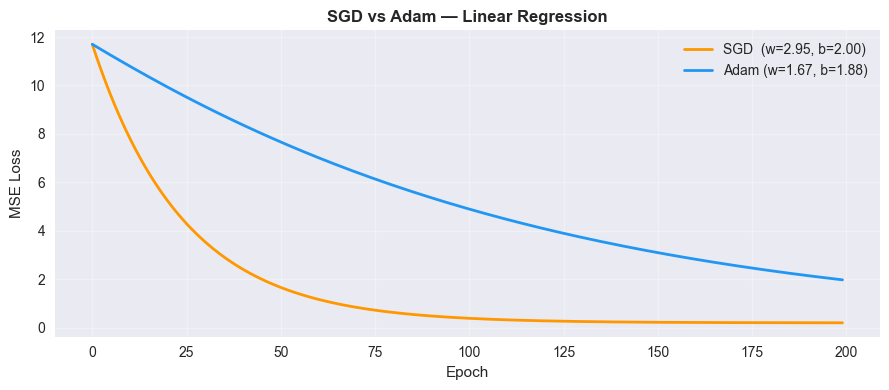

In [17]:
# TASK 12 — SGD vs Adam
torch.manual_seed(42)
X_reg = torch.randn(100, 1)
y_reg = 3 * X_reg + 2 + torch.randn(100, 1) * 0.5

def train_linear(optimizer_class, lr, epochs=200):
    torch.manual_seed(0)
    model_l = nn.Linear(1, 1)
    opt     = optimizer_class(model_l.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    losses  = []
    for _ in range(epochs):
        pred = model_l(X_reg)
        loss = loss_fn(pred, y_reg)
        opt.zero_grad()
        loss.backward()
        opt.step()
        losses.append(loss.item())
    w = model_l.weight.item()
    b = model_l.bias.item()
    return losses, w, b

losses_sgd,  w_sgd,  b_sgd  = train_linear(optim.SGD,  lr=0.01)
losses_adam, w_adam, b_adam = train_linear(optim.Adam, lr=0.01)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(losses_sgd,  color='#FF9800', linewidth=2, label=f'SGD  (w={w_sgd:.2f}, b={b_sgd:.2f})')
ax.plot(losses_adam, color='#2196F3', linewidth=2, label=f'Adam (w={w_adam:.2f}, b={b_adam:.2f})')
ax.set_title('SGD vs Adam — Linear Regression', fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE Loss')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ── TEACHER NOTE ─────────────────────────────────────────────────────────────
# Adam converges faster — typically 5-10× fewer epochs to same loss level
# Both converge to w≈3, b≈2 (the true parameters)
# Adam doesn't ALWAYS win — for very simple convex problems SGD with
# momentum can match it; for non-convex problems Adam is nearly always better
# ─────────────────────────────────────────────────────────────────────────────

---
# Part 6 — The Training Loop

## The Five Steps — Every Single Epoch

```python
# Step 1 — Forward pass: compute predictions
outputs = model(X_batch)

# Step 2 — Compute loss
loss = criterion(outputs, y_batch)

# Step 3 — Zero gradients (BEFORE backward — not after)
optimizer.zero_grad()

# Step 4 — Backward pass: compute gradients
loss.backward()

# Step 5 — Update parameters
optimizer.step()
```

**Why `zero_grad()` before `backward()`?** Because PyTorch accumulates gradients (as you proved in Task 6). You must zero them before computing new ones, otherwise you are updating with a sum of all previous gradients.

**Why not zero AFTER `step()`?** You could — but convention is before `backward()` because it makes the intent clear: "I am about to compute fresh gradients for this batch."

## Validation — What Changes

```python
model.eval()                    # disable dropout / freeze batchnorm
with torch.no_grad():           # disable gradient tracking (faster + less memory)
    val_outputs = model(X_val)
    val_loss    = criterion(val_outputs, y_val)
```

`torch.no_grad()` tells PyTorch: do NOT build a computational graph for these operations. No gradient tracking needed — saves memory and speeds up evaluation significantly.

In [18]:
# ── TASK 13 — Implement train_epoch() ────────────────────────────────────────
# A reusable function that runs ONE epoch over a DataLoader
# Returns: (mean_loss, accuracy) for that epoch
#
# Steps inside the loop:
#   1. Move batch to device
#   2. Forward pass
#   3. Compute loss
#   4. zero_grad
#   5. backward
#   6. optimizer.step
#   7. Track running loss and correct predictions

def train_epoch(model: nn.Module,
                loader: DataLoader,
                criterion: nn.Module,
                optimizer: optim.Optimizer,
                device: torch.device) -> tuple:
    """
    Run one training epoch.
    Returns (mean_loss, accuracy).
    """
    model.train()
    total_loss    = 0.0
    total_correct = 0
    total_samples = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # YOUR CODE HERE — steps 2-6
        outputs = model(X_batch) # Forward Pass
        loss = criterion(outputs, y_batch) # Loss Calculation
        optimizer.zero_grad() # Zero gradients
        loss.backward() # Backward Pass
        optimizer.step() # update
        

        # Track metrics
        total_loss    += loss.item() * len(y_batch)
        preds          = outputs.argmax(dim=1)
        total_correct += (preds == y_batch).sum().item()
        total_samples += len(y_batch)

    mean_loss = total_loss    / total_samples
    accuracy  = total_correct / total_samples
    return mean_loss, accuracy

print('train_epoch() defined ✅')

train_epoch() defined ✅


In [19]:
# ── TASK 14 — Implement evaluate() ───────────────────────────────────────────
# Same structure as train_epoch but:
#   - model.eval() instead of model.train()
#   - wrapped in torch.no_grad()
#   - NO optimizer steps
# Returns (mean_loss, accuracy)

def evaluate(model: nn.Module,
             loader: DataLoader,
             criterion: nn.Module,
             device: torch.device) -> tuple:
    """
    Evaluate model on a DataLoader.
    Returns (mean_loss, accuracy).
    """
    model.eval()
    total_loss    = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            # YOUR CODE HERE — forward pass only
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)


            total_loss    += loss.item() * len(y_batch)
            preds          = outputs.argmax(dim=1)
            total_correct += (preds == y_batch).sum().item()
            total_samples += len(y_batch)

    return total_loss / total_samples, total_correct / total_samples

print('evaluate() defined ✅')

evaluate() defined ✅


---
# Part 7 — DataLoader

## Why Not Just Load Everything at Once?

MNIST is 70,000 images × 784 pixels × 4 bytes = ~220MB. That fits in memory. ImageNet is 1.2 million images at multiple megabytes each — it does not.

More importantly: **mini-batch gradient descent** is better than full-batch even when memory allows:

```
Full-batch GD:    one gradient update per epoch
                  → smooth loss curve, slow convergence

Mini-batch GD:    many gradient updates per epoch
                  → noisier curve, much faster convergence
                  → also acts as regulariser (noise prevents sharp minima)
```

DataLoader handles all of this automatically:

| Parameter | Effect |
|-----------|--------|
| `batch_size=64` | 64 samples per gradient update |
| `shuffle=True` | Randomise order each epoch — prevents the model from memorising order |
| `num_workers=2` | Load batches in parallel (faster on CPU-bound pipelines) |

In [20]:
# ── TASK 15 — Build a DataLoader from a custom NumPy dataset ─────────────────
# This task uses synthetic data so you understand DataLoader mechanics
# before applying it to MNIST
#
# 1. Create synthetic classification data:
#      X_np: 1000 samples, 20 features (np.random.randn)
#      y_np: 1000 integer labels (np.random.randint(0, 5))
#
# 2. Convert to tensors (float32 for X, long for y)
#
# 3. Create a TensorDataset
#
# 4. Create a DataLoader with batch_size=64, shuffle=True
#
# 5. Iterate over the first 3 batches and print:
#      - Batch number
#      - X_batch shape
#      - y_batch shape
#      - First 5 labels
#
# 6. Count how many batches are in one full epoch
#    Print: "Total batches per epoch: N"

# TASK 15 — DataLoader mechanics
np.random.seed(42)
X_np = np.random.randn(1000, 20).astype(np.float32)
y_np = np.random.randint(0, 5, 1000)

X_t = torch.tensor(X_np)
y_t = torch.tensor(y_np, dtype=torch.long)

dataset = TensorDataset(X_t, y_t)
loader  = DataLoader(dataset, batch_size=64, shuffle=True)

for batch_idx, (X_batch, y_batch) in enumerate(loader):
    if batch_idx >= 3:
        break
    print(f'Batch {batch_idx+1}: X={X_batch.shape}, y={y_batch.shape}, labels={y_batch[:5].tolist()}')

print(f'\nTotal batches per epoch: {len(loader)}')
print(f'(1000 samples / 64 batch_size = {1000/64:.1f} → {len(loader)} batches, last batch smaller)')

# ── TEACHER NOTE ─────────────────────────────────────────────────────────────
# len(loader) = ceil(1000 / 64) = 16 batches
# The last batch has 1000 - 15*64 = 40 samples (smaller)
# drop_last=True drops the last partial batch — useful for BatchNorm
# (BN with batch_size=1 is numerically unstable)
# ─────────────────────────────────────────────────────────────────────────────

# 📝 With 1000 samples and batch_size=64, how many batches per epoch?
# What happens to the last batch if 1000 is not divisible by 64?
# ...

Batch 1: X=torch.Size([64, 20]), y=torch.Size([64]), labels=[1, 0, 2, 1, 0]
Batch 2: X=torch.Size([64, 20]), y=torch.Size([64]), labels=[4, 0, 2, 3, 2]
Batch 3: X=torch.Size([64, 20]), y=torch.Size([64]), labels=[2, 4, 2, 0, 3]

Total batches per epoch: 16
(1000 samples / 64 batch_size = 15.6 → 16 batches, last batch smaller)


---
# 🔢 Lab — MNIST Digit Classification

## The Dataset

MNIST is the "Hello World" of deep learning:
- **70,000 handwritten digit images** (60,000 train, 10,000 test)
- Each image: **28×28 pixels**, grayscale
- Labels: **0 through 9**
- Baseline (random): 10% accuracy
- Our target: **>97% test accuracy**

## Architecture Plan

```
Input:    784 (28×28 flattened)
          ↓
Dense:    256, ReLU, BatchNorm, Dropout(0.3)
          ↓
Dense:    128, ReLU, BatchNorm, Dropout(0.2)
          ↓
Output:   10 (raw logits)
```

## Pipeline

```
Download MNIST → Create DataLoaders → Build Model
→ Train 10 epochs → Plot curves → Final evaluation
→ Confusion matrix → Inspect errors
```

100.0%
100.0%
100.0%
100.0%


Train: 54,000  Val: 6,000  Test: 10,000


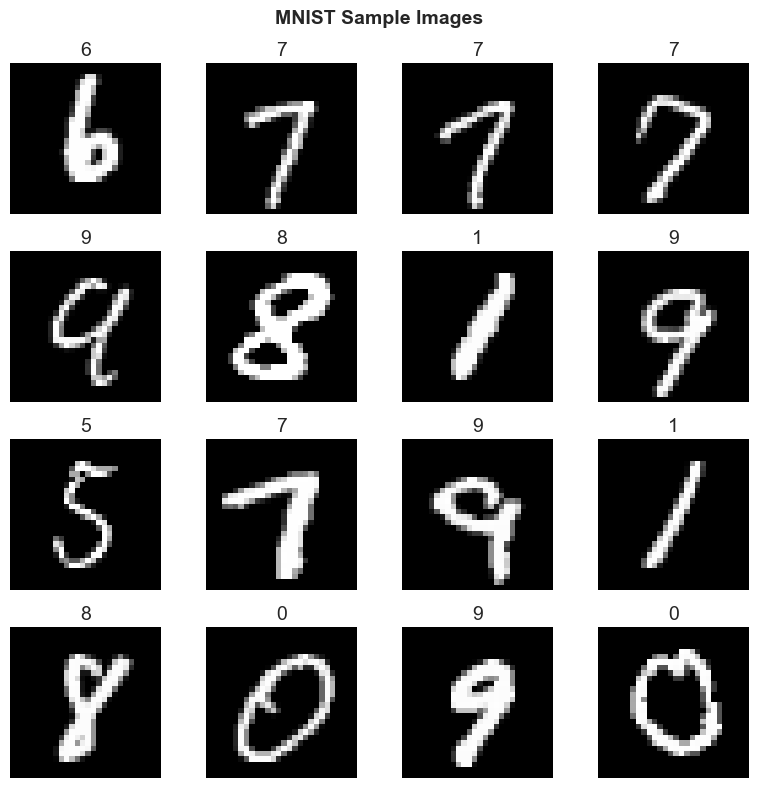

In [21]:
# ── TASK 16 — Load MNIST, create DataLoaders, visualise samples ───────────────
#
# 1. Define transform: ToTensor() + Normalize(mean=(0.1307,), std=(0.3081,))
#    These are the official MNIST mean and std
#
# 2. Download train and test sets using torchvision.datasets.MNIST
#
# 3. Split train set into train (54,000) and validation (6,000)
#    Use torch.utils.data.random_split
#
# 4. Create DataLoaders:
#    train_loader: batch_size=64, shuffle=True
#    val_loader:   batch_size=256, shuffle=False
#    test_loader:  batch_size=256, shuffle=False
#
# 5. Print dataset sizes
#
# 6. Visualise 16 sample images in a 4×4 grid
#    Show the true label as the title of each subplot
#    Use cmap='gray'

# YOUR CODE HERE
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])


train_full = torchvision.datasets.MNIST(
    root ='./data', 
    train = True, 
    download=True, 
    transform = transform
)
test_set = torchvision.datasets.MNIST(
    root ='./data', 
    train = False, 
    download=True, 
    transform = transform
)

from torch.utils.data import random_split
train_set, val_set = random_split(train_full, [54000, 6000], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_set, batch_size=64,  shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_set,   batch_size=256, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_set,  batch_size=256, shuffle=False, num_workers=0)

print(f'Train: {len(train_set):,}  Val: {len(val_set):,}  Test: {len(test_set):,}')


images, labels = next(iter(train_loader))

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(images[i].squeeze(), cmap='gray')
    ax.set_title(str(labels[i].item()), fontsize=14)
    ax.axis('off')
plt.suptitle('MNIST Sample Images', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 📝 Why do we normalise with mean=0.1307 and std=0.3081?
# What would happen if we skipped normalisation?
# ...

In [24]:
# ── TASK 17 — Build the MNIST MLP ────────────────────────────────────────────
# Architecture:
#   Flatten (28×28 → 784)
#   Linear(784, 256) → BatchNorm1d(256) → ReLU → Dropout(0.3)
#   Linear(256, 128) → BatchNorm1d(128) → ReLU → Dropout(0.2)
#   Linear(128, 10)  ← raw logits, no activation
#
# Notes:
#   - MNIST images arrive as shape (batch, 1, 28, 28)
#   - First operation in forward() must flatten to (batch, 784)
#     Use x.view(x.size(0), -1) or nn.Flatten()
#   - Do NOT add softmax — CrossEntropyLoss handles it
#
# After building:
#   - Move model to device
#   - Print architecture
#   - Print total parameter count

class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        # YOUR CODE HERE
        self.net = nn.Sequential(
            nn.Flatten(),# (batch, 1, 28,28) ----> (batch, 784)
            nn.Linear(784, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 10)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # YOUR CODE HERE
        return self.net(x)
    
    


mnist_model = MNISTClassifier().to(device)
print(mnist_model)
n_params = sum(p.numel() for p in mnist_model.parameters() if p.requires_grad)
print(f'\nTotal parameters: {n_params:,}')

# Sanity check
sample_batch, _ = next(iter(train_loader))
out = mnist_model(sample_batch.to(device))
print(f'Output shape: {out.shape}  (expected: [{sample_batch.size(0)}, 10])')

MNISTClassifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=256, out_features=128, bias=True)
    (6): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
    (9): Linear(in_features=128, out_features=10, bias=True)
  )
)

Total parameters: 235,914
Output shape: torch.Size([64, 10])  (expected: [64, 10])


In [25]:
# ── TASK 18 — Train the MNIST model for 10 epochs ────────────────────────────
# Use:
#   criterion = nn.CrossEntropyLoss()
#   optimizer = torch.optim.Adam(mnist_model.parameters(), lr=0.001)
#
# For each epoch:
#   - Call train_epoch() → get train_loss, train_acc
#   - Call evaluate()    → get val_loss,   val_acc
#   - Print: Epoch N/10 | Train Loss: X.XXXX | Val Loss: X.XXXX | Val Acc: XX.XX%
#
# Track all four metrics in lists for plotting

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(mnist_model.parameters(), lr=0.001)

n_epochs      = 10
train_losses  = []
val_losses    = []
train_accs    = []
val_accs      = []

# YOUR CODE HERE
for epoch in range(1, n_epochs + 1):
    tr_loss, tr_acc = train_epoch(mnist_model, train_loader, criterion, optimizer, device)
    vl_loss, vl_acc = evaluate(mnist_model, val_loader, criterion, device)

    train_losses.append(tr_loss)
    val_losses.append(vl_loss)
    train_accs.append(tr_acc)
    val_accs.append(vl_acc)

    print(f'Epoch {epoch:2d}/{n_epochs} | '
          f'Train Loss: {tr_loss:.4f} Acc: {tr_acc*100:.2f}% | '
          f'Val Loss: {vl_loss:.4f} Acc: {vl_acc*100:.2f}%')


# 📝 Is the validation loss higher or lower than the training loss?
# What would it mean if val_loss started INCREASING while train_loss kept decreasing?
# ...

Epoch  1/10 | Train Loss: 0.2989 Acc: 91.61% | Val Loss: 0.1279 Acc: 96.07%
Epoch  2/10 | Train Loss: 0.1502 Acc: 95.41% | Val Loss: 0.0926 Acc: 97.13%
Epoch  3/10 | Train Loss: 0.1173 Acc: 96.31% | Val Loss: 0.0919 Acc: 97.13%
Epoch  4/10 | Train Loss: 0.0994 Acc: 96.98% | Val Loss: 0.0744 Acc: 97.73%
Epoch  5/10 | Train Loss: 0.0883 Acc: 97.17% | Val Loss: 0.0728 Acc: 97.72%
Epoch  6/10 | Train Loss: 0.0794 Acc: 97.48% | Val Loss: 0.0660 Acc: 98.03%
Epoch  7/10 | Train Loss: 0.0727 Acc: 97.56% | Val Loss: 0.0676 Acc: 97.77%
Epoch  8/10 | Train Loss: 0.0663 Acc: 97.81% | Val Loss: 0.0629 Acc: 98.13%
Epoch  9/10 | Train Loss: 0.0640 Acc: 97.90% | Val Loss: 0.0583 Acc: 98.15%
Epoch 10/10 | Train Loss: 0.0574 Acc: 98.13% | Val Loss: 0.0629 Acc: 98.08%


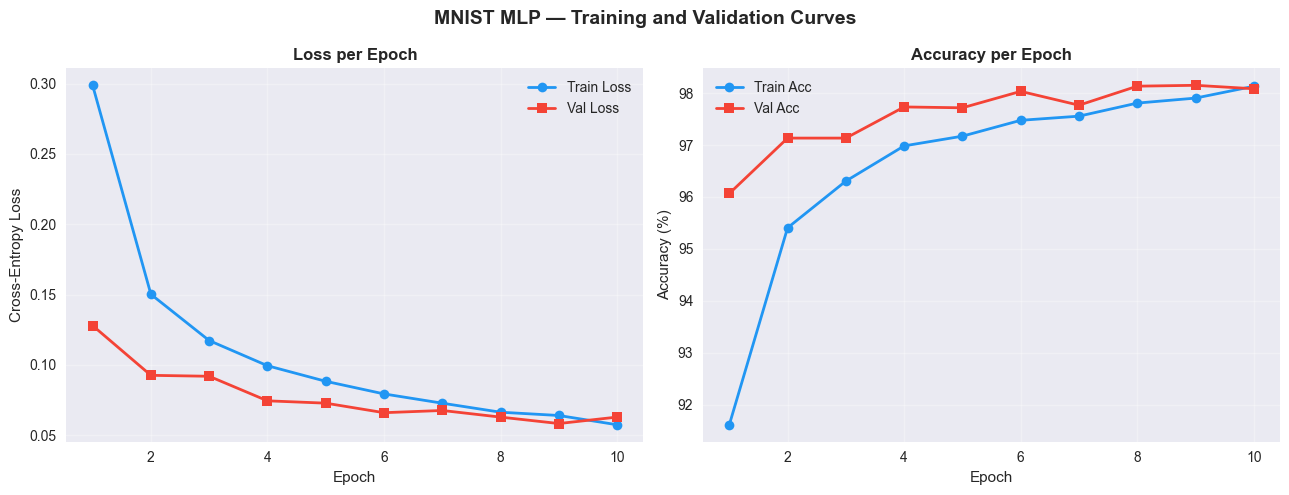

In [26]:
# TASK 19 — Learning curves
epochs_range = range(1, n_epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(epochs_range, train_losses, 'o-', color='#2196F3', linewidth=2, label='Train Loss')
axes[0].plot(epochs_range, val_losses,   's-', color='#F44336', linewidth=2, label='Val Loss')
axes[0].set_title('Loss per Epoch', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, [a*100 for a in train_accs], 'o-', color='#2196F3', linewidth=2, label='Train Acc')
axes[1].plot(epochs_range, [a*100 for a in val_accs],   's-', color='#F44336', linewidth=2, label='Val Acc')
axes[1].set_title('Accuracy per Epoch', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('MNIST MLP — Training and Validation Curves', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Test Loss: 0.0578   Test Accuracy: 98.28%

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.98      0.98      1032
           3       0.98      0.99      0.99      1010
           4       0.97      0.98      0.98       982
           5       0.99      0.99      0.99       892
           6       0.99      0.98      0.99       958
           7       0.98      0.98      0.98      1028
           8       0.98      0.98      0.98       974
           9       0.98      0.97      0.98      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



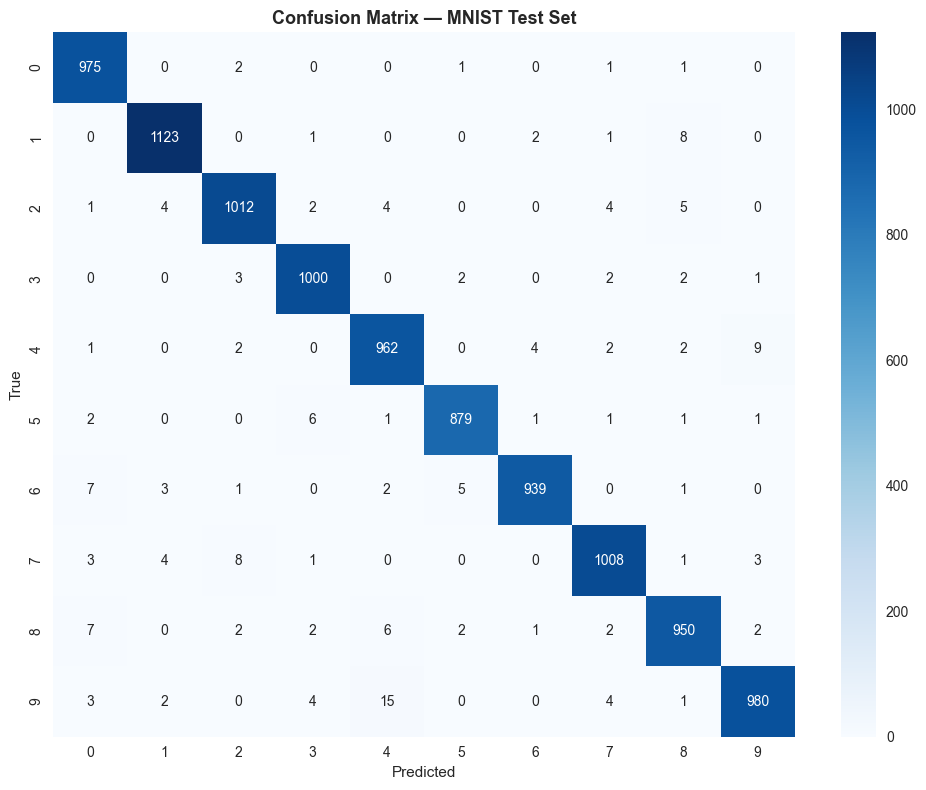


Total correctly classified: 9828/10000 (98.28%)


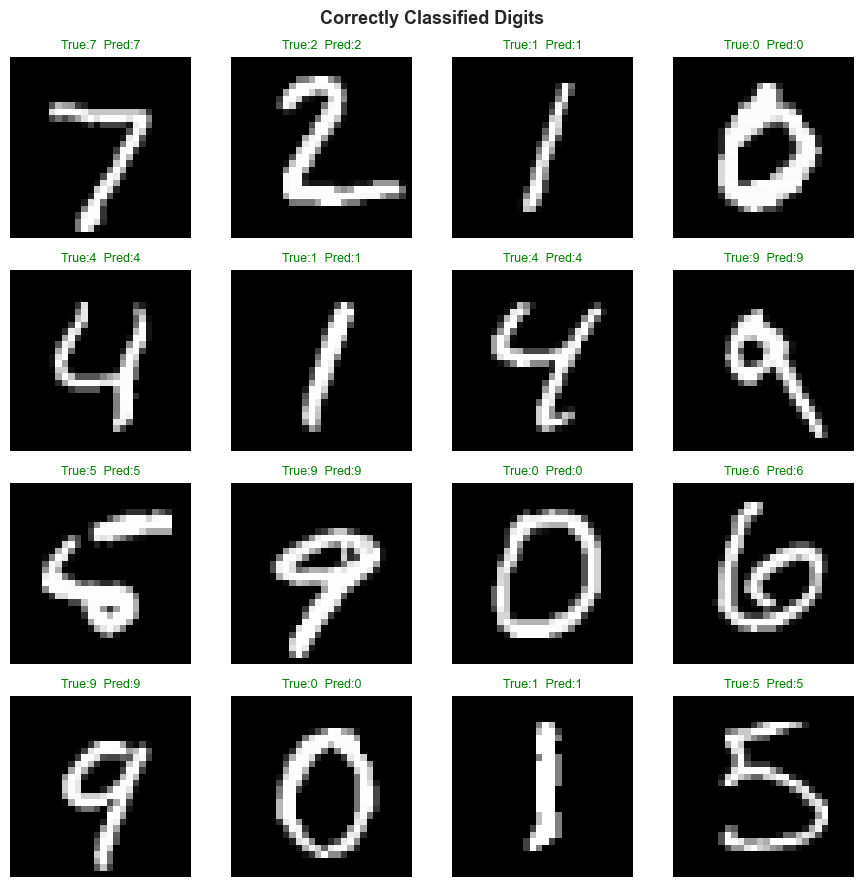


Total misclassified: 172/10000 (1.72%)


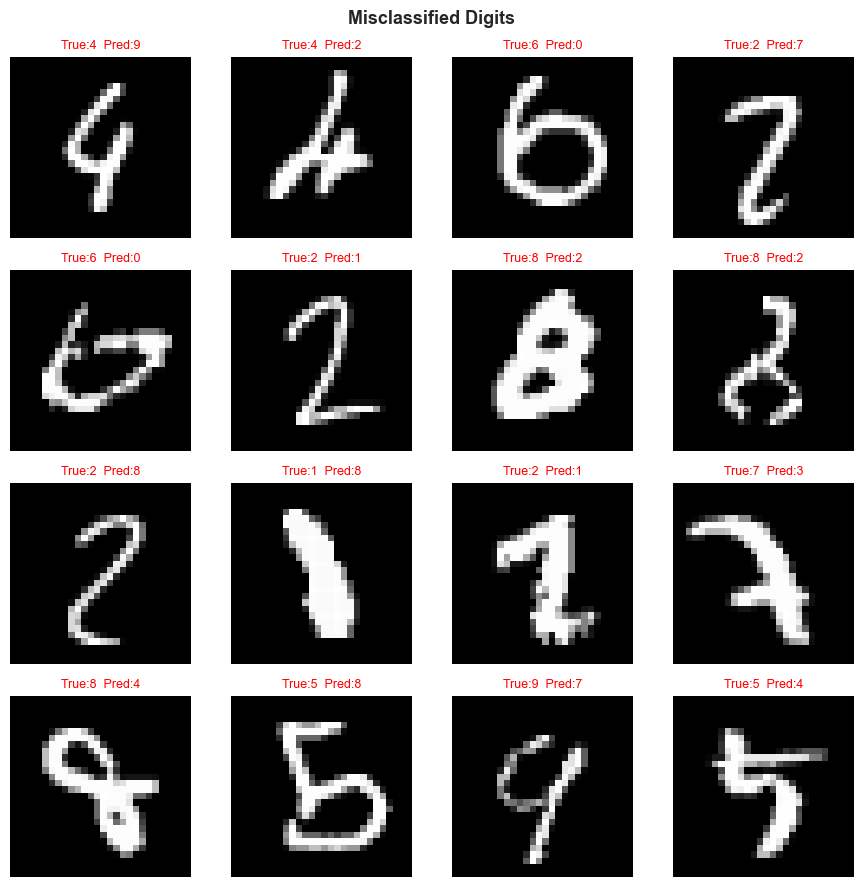

In [27]:
# ── TASK 20 — Final evaluation: classification report + confusion matrix ──────
#             + visualise correct and incorrect predictions
#
# Step 1: Run evaluate() on test_loader, print test loss and accuracy
#
# Step 2: Collect ALL predictions and true labels from the test set
#   (Loop over test_loader with model.eval() + torch.no_grad())
#
# Step 3: Print sklearn classification_report with target_names=['0','1',...,'9']
#
# Step 4: Plot confusion matrix as a heatmap (sns.heatmap, annot=True, fmt='d')
#
# Step 5: Visualise misclassified digits
#   Find indices where prediction != true label
#   Show 16 of them in a 4×4 grid
#   Title each subplot: "True: X  Pred: Y"

# Step 1 — test accuracy
test_loss, test_acc = evaluate(mnist_model, test_loader, criterion, device)
print(f'Test Loss: {test_loss:.4f}   Test Accuracy: {test_acc*100:.2f}%')

# Steps 2-4 — YOUR CODE HERE
all_preds , all_labels = [], []
all_images = []
mnist_model.eval()

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        out = mnist_model(X_batch.to(device))
        preds = out.argmax(dim=1).cpu()
        all_preds.append(preds)
        all_labels.append(y_batch)
        all_images.append(X_batch)


all_preds  = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()
all_images = torch.cat(all_images)

# Classification report
print('\n' + classification_report(all_labels, all_preds,
                                    target_names=[str(i) for i in range(10)]))

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=range(10), yticklabels=range(10))
ax.set_title('Confusion Matrix — MNIST Test Set', fontweight='bold', fontsize=13)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
plt.tight_layout()
plt.show()

# Step 5 — visualise errors
# YOUR CODE HERE


# Perfectly classified digits
correct = np.where(all_preds == all_labels)[0]
print(f'\nTotal correctly classified: {len(correct)}/{len(all_labels)} ({len(correct)/len(all_labels)*100:.2f}%)')

fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for i, ax in enumerate(axes.flatten()):
    idx = correct[i]
    ax.imshow(all_images[idx].squeeze(), cmap='gray')
    ax.set_title(f'True:{all_labels[idx]}  Pred:{all_preds[idx]}',
                 fontsize=9, color='green')
    ax.axis('off')
plt.suptitle('Correctly Classified Digits', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Misclassified digits
errors = np.where(all_preds != all_labels)[0]
print(f'\nTotal misclassified: {len(errors)}/{len(all_labels)} ({len(errors)/len(all_labels)*100:.2f}%)')

fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for i, ax in enumerate(axes.flatten()):
    idx = errors[i]
    ax.imshow(all_images[idx].squeeze(), cmap='gray')
    ax.set_title(f'True:{all_labels[idx]}  Pred:{all_preds[idx]}',
                 fontsize=9, color='red')
    ax.axis('off')
plt.suptitle('Misclassified Digits', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 📝 Which digit pairs does the model confuse most often?
# (Look at the confusion matrix off-diagonal elements)
# Does that confusion make sense visually?
# ...

---
# 📝 Day 11 Summary

| Concept | Key Takeaway |
|---------|-------------|
| **Tensor** | PyTorch's n-dimensional array — can live on GPU, tracks gradients |
| **from_numpy** | Shares memory — modifying NumPy array changes the tensor |
| **requires_grad** | Tells PyTorch to track operations for automatic differentiation |
| **backward()** | Traverses the computational graph and computes all gradients |
| **zero_grad()** | Must be called before backward() — gradients accumulate otherwise |
| **nn.Module** | Base class for all models — automatic parameter tracking, device moving |
| **CrossEntropyLoss** | Takes raw logits — do NOT apply softmax first |
| **Adam** | Adaptive learning rates per parameter — better default than SGD |
| **model.train()** | Enables Dropout randomness and BatchNorm updates |
| **model.eval()** | Disables Dropout, freezes BatchNorm — always use for val/test |
| **torch.no_grad()** | Disables gradient tracking — faster and less memory during evaluation |
| **DataLoader** | Batching + shuffling — use mini-batch GD, not full-batch |

---
# 🏠 Homework

1. Experiment with three different learning rates: `[0.0001, 0.001, 0.01]`. Train for 5 epochs each. Plot all three loss curves on the same axes. Which diverges? Which is too slow?

2. Experiment with batch sizes `[32, 64, 256, 1024]`. For each, train for 5 epochs and record final val accuracy. How does batch size affect convergence speed and final accuracy?

3. Train the same architecture WITHOUT Dropout and WITHOUT BatchNorm. Compare the loss curves with and without regularisation. At which epoch does overfitting appear without regularisation?

4. Add a third hidden layer (64 units, ReLU) to the architecture. Does the extra depth help or hurt accuracy on MNIST? Why might very deep networks not always outperform shallower ones on simple datasets?

5. In your own words, explain what would happen to your training if you:
   - Forgot `optimizer.zero_grad()`
   - Forgot `model.eval()` during validation
   - Applied softmax before `CrossEntropyLoss`
   - Used `torch.from_numpy()` and then modified the original array